# 5 · How much of the sausage's history should a prediction see?

By default a prediction looks at **one window of 10 uplinks**, which spans minutes. The models then classify the
*current level* of moisture, conductivity and temperature, but not how the sausage got there. Ripening is a process
of weeks, so two ways to give the models more time are compared here:

* **Longer windows** (`window_size`): more uplinks per window, e.g. 30 (≈ 1.5 h). Smoother statistics, still a snapshot.
* **Context features** (`context`): per signal, mean, spread and **trend per day** over the last 24 h and/or 7 days
  before the window (`WindowFeatures` in `ml_core/windowing.py`). This is what drying looks like: moisture falling by
  x % per day, slower and slower.

Everything else stays as in notebook 3 (feature set, augmentation); every model family is compared.

**Keeping the schedule out.** Context only uses the past of the same sausage, never the time since the start. Windows
without the full horizon of history (the first 24 h / 7 days of a run) are left out of training and evaluation, so a
model cannot learn "short history → early phase". For a fair comparison, *every* configuration here is scored without the
first `SKIP_START` of each run (the longest horizon compared), i.e. on the same windows; the scores are therefore a
little lower than in notebook 3 (the first days are Umrötung, the easiest phase). In the demonstrator, missing history
is filled by repeating the earliest stretch ("as if constant") and marked in the UI.

**Cost in the demonstrator:** with 7-day context a live prediction needs 7 days of uplinks to be fully informed (the
case has no sausage anyway; replay and simulation use the recorded history). The feature computation per prediction
grows from microseconds to a few milliseconds.

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath(".."))  # project root, so ml_core is importable
import matplotlib.pyplot as plt
import pandas as pd
from ml_core import data
from ml_core.training import (ALL_MODELS, DEFAULT_AUGMENTATION, DEFAULT_FEATURE_SET, DEFAULT_STRIDE, PROGRESSION_UNTIL,
                              compare_feature_sets, describe_windows, load_windows)
from ml_core.windowing import horizon
pd.set_option("display.width", 200)

In [2]:
CONVERTED_DIR = data.CONVERTED_DIR
FEATURE_SET = DEFAULT_FEATURE_SET
AUGMENT = DEFAULT_AUGMENTATION
# (uplinks per window, context horizons). Each configuration costs models × 6 fits.
CONFIGS = [(10, ()), (30, ()), (10, ("24h",)), (10, ("24h", "7d"))]
STRIDE = DEFAULT_STRIDE
SKIP_START = None    # None = the longest context horizon in CONFIGS: every configuration is scored on the same windows
MODELS = list(ALL_MODELS)
QUICK = False
N_JOBS = -1

In [3]:
if SKIP_START is None:
    SKIP_START = max((horizon(h) for _, ctx in CONFIGS for h in ctx), default=pd.Timedelta(0))
print("Scored without the first", SKIP_START, "of every run")
variant = FEATURE_SET + "".join("+" + a for a in AUGMENT)
tables, progressions, classes = [], {}, None
for window_size, context in CONFIGS:
    label = describe_windows(window_size, context)
    print(f"\n=== {label} ===")
    w = load_windows(CONVERTED_DIR, window_size=window_size, stride=STRIDE, context=context, skip_start=SKIP_START)
    u = load_windows(CONVERTED_DIR, "series_2_*.csv", window_size, STRIDE, annotated=False, classes=w.classes,
                     context=context, skip_start=SKIP_START)
    classes = w.classes
    t, prog = compare_feature_sets(w, u, [variant], keys=MODELS, quick=QUICK, n_jobs=N_JOBS)
    tables.append(t.reset_index().assign(windows=label).drop(columns="variant"))
    progressions.update({(label, key): p for (_, key), p in prog.items()})
table = pd.concat(tables).set_index(["windows", "model"])
table

Scored without the first 7 days 00:00:00 of every run

=== 10 uplinks ===


series_1_sausage_1: 41,462 rows → 19,388 windows
series_1_sausage_2: 41,479 rows → 19,395 windows
series_1_sausage_3: 41,468 rows → 19,392 windows
series_1_sausage_4: 41,472 rows → 19,394 windows
series_1_sausage_5: 41,465 rows → 19,388 windows


series_2_sausage_1: 79,919 rows → 38,860 windows
series_2_sausage_2: 79,903 rows → 38,852 windows
series_2_sausage_3: 79,915 rows → 38,858 windows
series_2_sausage_4: 79,920 rows → 38,861 windows
series_2_sausage_5: 79,930 rows → 38,866 windows
Augmenting the training data (calibration_large): 2 copies per sausage …


24 fits (1 variants × 4 models × folds) in parallel …


temperature_difference+calibration_large · Logistic Regression: balanced acc 0.719 (folds 0.58, 0.79, 0.64, 0.80, 0.79)


temperature_difference+calibration_large · Random Forest: balanced acc 0.783 (folds 0.58, 0.87, 0.92, 0.73, 0.81)


... (19 outputs left out)

temperature_difference+calibration_large · Logistic Regression: balanced acc 0.831 (folds 0.76, 0.77, 0.90, 0.79, 0.93)


temperature_difference+calibration_large · Random Forest: balanced acc 0.882 (folds 0.65, 0.96, 0.95, 0.90, 0.95)
temperature_difference+calibration_large · MLP (neural net): balanced acc 0.841 (folds 0.73, 0.74, 0.94, 0.84, 0.96)


temperature_difference+calibration_large · Gradient Boosting: balanced acc 0.873 (folds 0.64, 0.91, 0.93, 0.93, 0.95)


features  series 1: balanced acc  ± std  worst sausage  series 2: phase order ρ  series 2: backwards share
windows                     model                                                                                                                          
10 uplinks                  Logistic Regression        24                   0.719  0.092          0.579                    0.806                      0.046
                            Random Forest              24                   0.783  0.118          0.582                    0.855                      0.002
                            MLP (neural net)           24                   0.741  0.066          0.612                    0.838                      0.043
                            Gradient Boosting          24                   0.729  0.091          0.582                    0.838                      0.058
30 uplinks                  Logistic Regression        24                   0.754  0.067          0.632                    0.795                      0.073
                            Random Forest              24                   0.792  0.123          0.581                    0.854                      0.001
                            MLP (neural net)           24                   0.759  0.103          0.581                    0.836                      0.079
                            Gradient Boosting          24                   0.767  0.116          0.582                    0.839                      0.047
10 uplinks + 24h context    Logistic Regression        36                   0.782  0.086          0.626                    0.679                      0.114
                            Random Forest              36                   0.825  0.126          0.600                    0.786                      0.045
                            MLP (neural net)           36                   0.766  0.099          0.592                    0.661                      0.144
                            Gradient Boosting          36                   0.837  0.134          0.595                    0.778                      0.108
10 uplinks + 24h/7d context Logistic Regression        48                   0.831  0.072          0.758                    0.758                      0.111
                            Random Forest              48                   0.882  0.116          0.653                    0.831                      0.015
                            MLP (neural net)           48                   0.841  0.099          0.728                    0.612                      0.204
                            Gradient Boosting          48                   0.873  0.117          0.640                    0.854                      0.052

## Predicted phase on series 2 per window configuration (smoothed over one day)

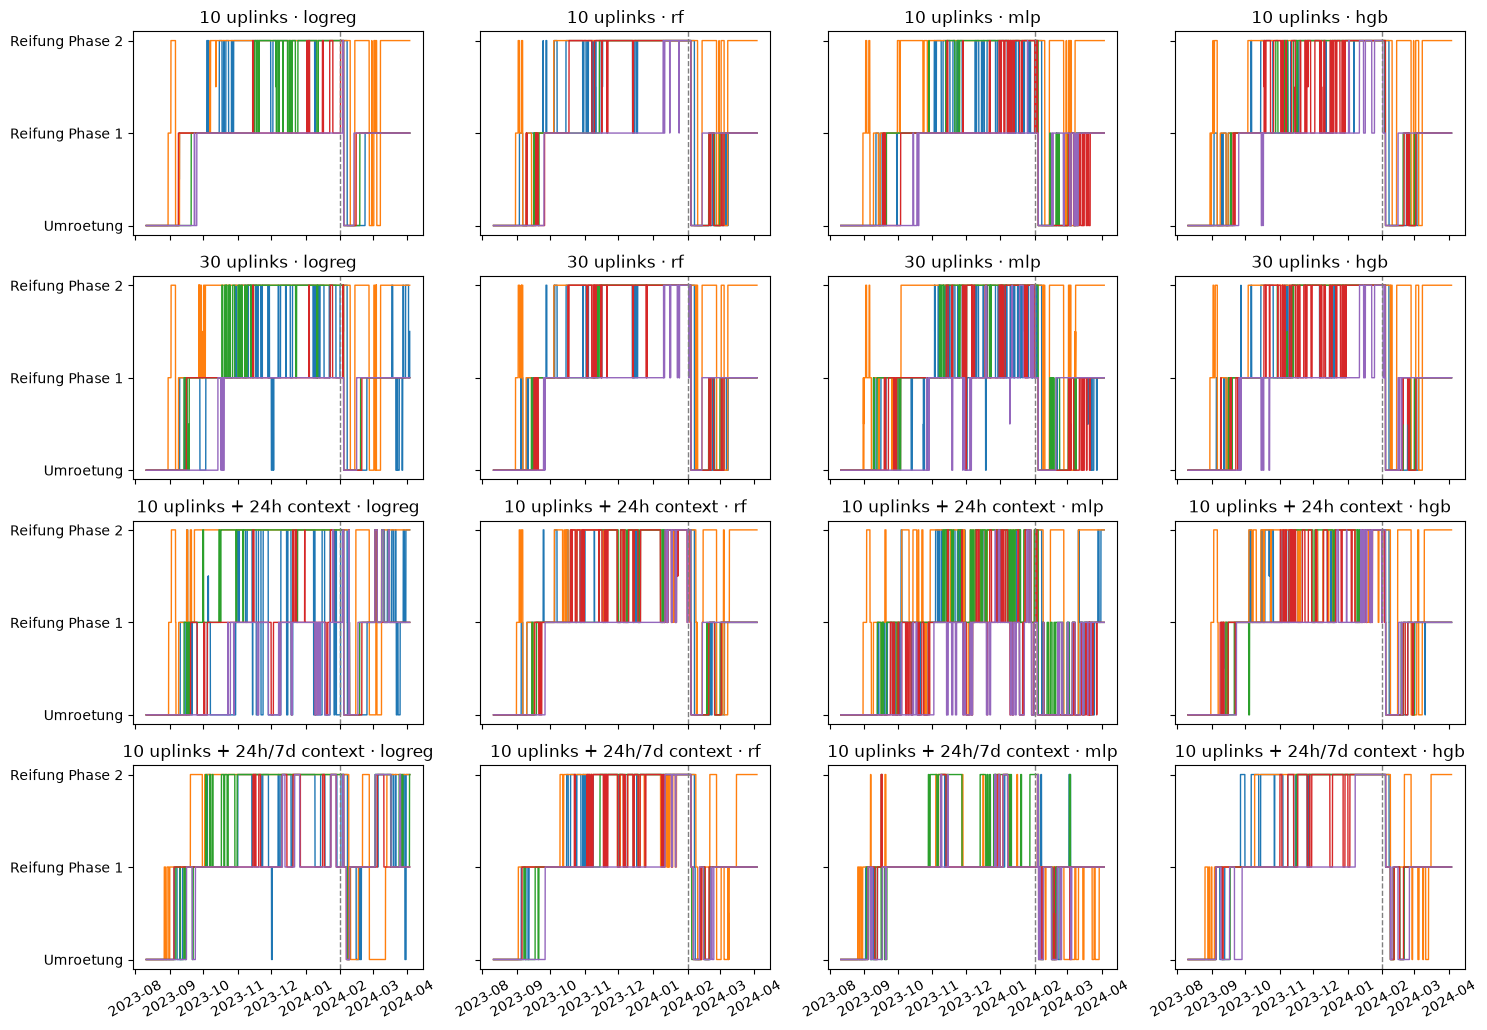

In [4]:
labels = list(dict.fromkeys(label for label, _ in progressions))
keys = [k for k in MODELS if any(key == k for _, key in progressions)]
fig, axes = plt.subplots(len(labels), len(keys), figsize=(15, 2.6 * len(labels)), sharex=True, sharey=True, squeeze=False)
for i, label in enumerate(labels):
    for j, key in enumerate(keys):
        ax = axes[i][j]
        for rec, s in progressions[(label, key)].items():
            ax.plot(s.index, s.values, lw=1)
        if PROGRESSION_UNTIL:
            ax.axvline(pd.Timestamp(PROGRESSION_UNTIL), color="grey", ls="--", lw=1)
        ax.set(title=f"{label} · {key}", yticks=range(len(classes)), yticklabels=classes)
        ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

**How to read it:** a configuration is worth its cost if it improves the mean *and* the worst sausage on series 1
and keeps (or improves) the phase order on series 2. To adopt one, set `DEFAULT_WINDOW_SIZE` / `DEFAULT_CONTEXT` in
`ml_core/training.py` (or `WINDOW_SIZE`/`CONTEXT` in notebooks 2 and 3) and re-run notebooks 2 and 3. The
demonstrator reads the window settings from the exported models, nothing else needs changing.